# Transition-matrix analysis

A loose version of the paper's three-stage analysis of DECIFRA transition matrices, run on
subjects the fine-tuned model has not seen: (1) functional patterns, the common layouts of the
strongest connections; (2) class-specific patterns, the patterns averaged per class; (3)
second-order dynamics, how often subjects of each class move between these states. Connectograms
draw the patterns as directed graphs.

The matrices come from the best cell of a fine-tuning experiment (its test fold plus extra test
sets such as the FBIRN holdout). Section 2 exposes `best_cell`, `load_cell`, `derive` and `merge`,
so more data (other cells, folds or datasets) can be added before the stages run.

## 1. Settings

In [8]:
import os, re, sys, glob, string
from importlib import import_module

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import FancyArrowPatch, Patch, Wedge
from matplotlib.path import Path
from omegaconf import OmegaConf
from scipy.stats import false_discovery_control, kruskal, mannwhitneyu
from sklearn.cluster import AgglomerativeClustering, Birch, KMeans

EXPERIMENT = "assets/logs/2_finetune-fbirn-DECIFRA"   # fine-tuning experiment, relative to the repo root
EXPERIMENT = "assets/logs/2_finetune-fbirn-DECIFRA_MS-default"   # fine-tuning experiment, relative to the repo root
METRIC = "test_auc"                       # test_log.csv column that picks the best cell
TEST_SETS = {"holdout": "fbirn_holdout"}  # extra unseen subjects: name -> conf/dataset config
CLASS_NAMES = ["HC", "SZ"]                # label order (FBIRN diags: 0 = HC, 1 = SZ; None: 0, 1, ...)

PERCENTILE = 90    # masks keep |M| above this percentile of each matrix
MIN_SHARE = 0.05   # add patterns while each holds >= 5% of the masks
K_MAX = 12         # most patterns tried
DELTA_TOP = 15     # second-order deltas: show the top 15% |values|
ALPHA = 0.05       # FDR level of the group tests

ICN_CSV = "assets/data/ICN_coordinates_refined.csv"   # region names and domains (None: plain indices)
OUT_DIR = "assets/analysis/03_matrices"               # figures (None: don't save)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# repo root = first parent of the notebook dir that holds src/
ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "src")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
from src.registry import resolve_finetuning_dataset

if OUT_DIR:
    os.makedirs(os.path.join(ROOT, OUT_DIR), exist_ok=True)

In [9]:
# plot style, palette and color maps
INK, MUTED, EDGE = "#0b0b0b", "#898781", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 9,
    "axes.edgecolor": EDGE, "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
})
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SIGNED, ABS = "seismic", "inferno"     # signed matrices (centered at 0), non-negative ones
LINKS = LinearSegmentedColormap.from_list("links", plt.get_cmap("YlOrBr")(np.linspace(0.3, 1, 64)))   # connectogram edges


def regions(C):
    """Display order, short names and domains of C regions (ICN table if it fits, else indices)."""
    path = os.path.join(ROOT, ICN_CSV or "")
    icn = pd.read_csv(path) if os.path.isfile(path) else None
    if icn is None or len(icn) != C:
        if ICN_CSV:
            print(f"{ICN_CSV} is missing or does not list {C} regions: regions shown by index")
        return np.arange(C), [str(i) for i in range(C)], ["all"] * C

    # 'Superior temporal gyrus ([STG], 21)' -> 'STG (21)'
    def short(name):
        abbr, num = re.search(r"\[(.*?)\]", name), re.search(r"(\d+)\)", name)
        return (abbr.group(1) if abbr else name.split("(")[0].strip()) + (f" ({num.group(1)})" if num else "")

    doms = list(dict.fromkeys(icn.Domain))
    order = np.argsort([doms.index(d) for d in icn.Domain], kind="stable")
    return order, [short(n) for n in icn.ICN], list(icn.Domain)


def save(fig, name):
    if OUT_DIR:
        fig.savefig(os.path.join(ROOT, OUT_DIR, f"{name}.png"))


def by_domain(W):
    """Block means of a C x C matrix between domains."""
    idx = [[i for i in range(len(W)) if DOMAIN[i] == d] for d in DOMAINS]
    return np.array([[W[np.ix_(r, c)].mean() for c in idx] for r in idx])


def heatmap(ax, W, vmax=None, title=""):
    """C x C matrix in domain order (rows: to, columns: from); signed: seismic around 0, else inferno."""
    lim = vmax or np.abs(W).max()
    signed = W.min() < -1e-6 * lim    # ignore float noise below 0
    im = ax.imshow(W[np.ix_(ORDER, ORDER)], cmap=SIGNED if signed else ABS, vmin=-lim if signed else 0, vmax=lim,
                   interpolation="nearest")

    # domain blocks
    dom = [DOMAIN[i] for i in ORDER]
    cuts = [i for i in range(1, len(dom)) if dom[i] != dom[i - 1]]
    for c in cuts:
        ax.axhline(c - 0.5, color="black" if signed else "silver", lw=0.5)
        ax.axvline(c - 0.5, color="black" if signed else "silver", lw=0.5)

    # domain abbreviations at block centers
    starts, ends = [0] + cuts, cuts + [len(dom)]
    mids = [(s + e - 1) / 2 for s, e in zip(starts, ends)]
    abbr = ["".join(w[0] for w in dom[s].split()).upper() if " " in dom[s] else dom[s][:3].upper() for s in starts]
    ax.set_xticks(mids, abbr, rotation=90, fontsize=6)
    ax.set_yticks(mids, abbr, fontsize=6)
    ax.tick_params(length=0)
    ax.set_title(title)
    return im


def connectogram(ax, W, names, colors, groups=None, top=100 - PERCENTILE, fontsize=6):
    """Directed edges column -> row of the top `top`% off-diagonal |W|; returns the edge color scale."""
    n = len(W)
    groups = groups or [0] * n
    slot = np.arange(n) + np.cumsum([0] + [groups[i] != groups[i - 1] for i in range(1, n)])
    step = 2 * np.pi / (slot[-1] + 1 + (len(set(groups)) > 1))    # one free slot between groups
    ang = np.pi / 2 - step * slot                                  # clockwise from the top
    pos = np.c_[np.cos(ang), np.sin(ang)]

    # strongest edges, weakest drawn first; the two directions of a pair bend apart
    off = ~np.eye(n, dtype=bool)
    thr = np.percentile(np.abs(W[off]), 100 - top)
    to, src = np.nonzero(off & (np.abs(W) >= thr) & (W != 0))
    w = np.abs(W[to, src])
    s = (w - w.min()) / (w.max() - w.min() + 1e-12)
    for i, j, v in sorted(zip(to, src, s), key=lambda e: e[2]):
        d = pos[i] - pos[j]
        ctrl = (1 - 0.45 * np.linalg.norm(d)) * (pos[i] + pos[j]) / 2 + 0.08 * np.array([-d[1], d[0]])
        path = Path([pos[j], ctrl, pos[i]], [Path.MOVETO, Path.CURVE3, Path.CURVE3])
        ax.add_patch(FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=4 + 5 * v, lw=0.3 + 1.2 * v,
                                     color=LINKS(v), alpha=0.2 + 0.8 * v))

    # ring of nodes and radial labels
    for a, col, name in zip(ang, colors, names):
        ax.add_patch(Wedge((0, 0), 1.09, np.degrees(a - 0.42 * step), np.degrees(a + 0.42 * step), width=0.07,
                           color=col, lw=0))
        deg = np.degrees(a) % 360
        flip = 90 < deg < 270
        ax.text(1.12 * np.cos(a), 1.12 * np.sin(a), name, rotation=deg - 180 if flip else deg,
                rotation_mode="anchor", ha="right" if flip else "left", va="center", fontsize=fontsize, color=INK)
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal")
    ax.axis("off")
    return ScalarMappable(Normalize(w.min(), w.max()), LINKS)

## 2. Transition matrices

`best_cell` picks a fine-tuned model (best `METRIC` among cells that kept `best.pt`), `load_cell`
returns it with its unseen subjects (the cell's test fold and `TEST_SETS`), `derive` runs a model on
any data and `merge` pools the results. Add data at the end of this cell, before the stages run.

In [10]:
def best_cell(experiment=EXPERIMENT, metric=METRIC, fold=None):
    """Cell dir (k*/r*) with the best `metric` among finished cells that kept best.pt."""
    pattern = os.path.join(ROOT, experiment, "k*" if fold is None else f"k{fold:02d}", "r*")
    cells = [c for c in sorted(glob.glob(pattern))
             if os.path.exists(os.path.join(c, "best.pt")) and os.path.exists(os.path.join(c, "test_log.csv"))]
    if not cells:
        raise FileNotFoundError(f"no finished cell with best.pt: {pattern}")

    score = {c: pd.read_csv(os.path.join(c, "test_log.csv"))[metric].iloc[0] for c in cells}
    cell = (min if "loss" in metric else max)(score, key=score.get)
    print(f"{os.path.relpath(cell, ROOT)}: {metric} = {score[cell]:.3f}")
    return cell


def load_cell(cell, test_sets=TEST_SETS):
    """Fine-tuned model of a cell and its unseen subjects {name: (x, y)}: test fold + test_sets."""
    cfg = OmegaConf.load(os.path.join(cell, "config.yaml"))
    mcfg = OmegaConf.load(os.path.join(cell, "model_config.yaml"))
    model = getattr(import_module(f"src.models.{mcfg.module}"), mcfg.model_name)(mcfg)
    model.load_state_dict(torch.load(os.path.join(cell, "best.pt"), map_location="cpu"))
    if hasattr(model, "setup_finetuning"):    # DECIFRA_MS: pin the mixing weight
        model.setup_finetuning()
    model.zscore = bool(cfg.train.get("zscore", True))   # data prep of fine-tuning, used by derive
    model.to(DEVICE).eval()

    # test fold = rows of the main dataset, then the extra sets
    x, y = (np.asarray(a) for a in resolve_finetuning_dataset(cfg.dataset))
    idx = pd.read_csv(os.path.join(cell, "test_predictions.csv")).sample_idx.to_numpy()
    sets = {"test": (x[idx], y[idx])}
    for name, ds in test_sets.items():
        ds_cfg = OmegaConf.load(os.path.join(ROOT, "conf", "dataset", f"{ds}.yaml"))
        sets[name] = tuple(np.asarray(a) for a in resolve_finetuning_dataset(ds_cfg))
    return model, sets


@torch.no_grad()
def derive(model, x, y, name):
    """Run a model on (x, y): matrices M [subjects, time, to, from], predictions per subject and per matrix."""
    zscore = getattr(model, "zscore", True)
    loader = type(model).prepare_dataloader(x, y, shuffle=False, batch_size=32, zscore=zscore)
    M, prob, pred_t = [], [], []
    for batch in loader:
        logits, out = model(*(b.to(DEVICE) for b in batch[:-1]))
        M.append(out["matrices"].cpu().numpy())
        prob.append(torch.softmax(logits, 1).cpu().numpy())
        pred_t.append(out["time_logits"].argmax(-1).cpu().numpy())    # before averaging over time

    M, prob = np.concatenate(M), np.concatenate(prob)
    i = np.arange(M.shape[-1])
    M[..., i, i] = 0    # self-transitions are left out (identity in DECIFRA_MS)
    return {"M": M, "y": np.asarray(y), "prob": prob, "pred": prob.argmax(1), "pred_t": np.concatenate(pred_t),
            "set": np.full(len(y), name)}


def merge(*parts):
    """Pool derive() outputs (more sets, cells or datasets); scans are cut to the shortest."""
    T = min(p["M"].shape[1] for p in parts)
    cut = lambda k, a: a[:, :T] if k in ("M", "pred_t") else a
    return {k: np.concatenate([cut(k, p[k]) for p in parts]) for k in parts[0]}


cell = best_cell()
model, sets = load_cell(cell)
data = merge(*(derive(model, x, y, name) for name, (x, y) in sets.items()))

# more data goes here, e.g. another dataset scored by the same model:
#   x, y = resolve_finetuning_dataset(OmegaConf.load(os.path.join(ROOT, "conf/dataset/<name>.yaml")))
#   data = merge(data, derive(model, x, y, "<name>"))
# or the test folds of the best cell of every fold (all main subjects once):
#   parts = []
#   for k in range(5):
#       m, s = load_cell(best_cell(fold=k), test_sets={})
#       parts.append(derive(m, *s["test"], f"test{k}"))
#   data = merge(*parts)

N, T, C = data["M"].shape[:3]
CLASSES = CLASS_NAMES or [str(c) for c in range(data["prob"].shape[1])]
ORDER, NAMES, DOMAIN = regions(C)
DOMAINS = list(dict.fromkeys(DOMAIN[i] for i in ORDER))
DCOLOR = {d: SLOTS[i] if i < len(SLOTS) else MUTED for i, d in enumerate(DOMAINS)}

# correctly classified subjects and matrices (per-time-point prediction)
ok = data["pred"] == data["y"]
ok_t = data["pred_t"] == data["y"][:, None]

# subjects per set and class, accuracies
sets_ = pd.Series(data["set"], name="set")
table = pd.crosstab(sets_, pd.Series(np.array(CLASSES)[data["y"]], name="class"), margins=True, margins_name="all")
table = table.reindex(columns=CLASSES + ["all"], fill_value=0)
for col, hit in [("subject acc.", ok), ("matrix acc.", ok_t.mean(1))]:
    table[col] = pd.concat([pd.Series(hit).groupby(sets_).mean(), pd.Series({"all": hit.mean()})]).round(3)
display(table)
print(f"matrices: {N} subjects x {T} time points, {C} x {C} (rows: to, columns: from)")

assets/logs/2_finetune-fbirn-DECIFRA_MS-default/k03/r06: test_auc = 0.859


class,HC,SZ,all,subject acc.,matrix acc.
set,,,,,
holdout,8,8,16,0.688,0.683
test,31,28,59,0.746,0.713
all,39,36,75,0.733,0.706


matrices: 75 subjects x 140 time points, 53 x 53 (rows: to, columns: from)


## 3. Stage 1: functional patterns

Each correctly classified matrix (its own prediction, before averaging over time, matches the
subject's class) becomes a binary mask of its strongest connections (|M| above the `PERCENTILE`-th
percentile, so signs do not matter). BIRCH groups the masks and K-Means
refines its centroids. The number of patterns starts at the elbow of the inertia curve and grows
while every pattern holds at least `MIN_SHARE` of the masks. A pattern is the frequency of each
connection in its masks; patterns are named by share (A = most common).

7417 masks, elbow at k = 3, 3 patterns: A 36%, B 34%, C 30%


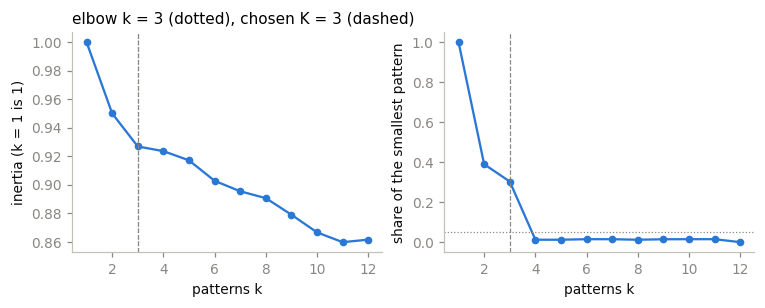

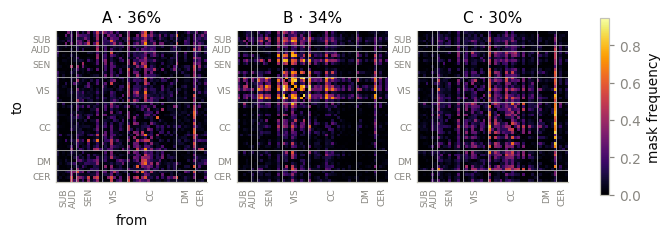

In [11]:
def masks(M):
    """Binary masks of |M| above PERCENTILE, one flattened mask per matrix."""
    a = np.abs(M.reshape(-1, M.shape[-2] * M.shape[-1]))
    return (a > np.percentile(a, PERCENTILE, axis=1, keepdims=True)).astype(np.float32)


def cluster(X, ks):
    """BIRCH -> K-Means for each k: {k: fitted KMeans}."""
    # masks are nearly equidistant (high dimension): subclusters need almost the data's radius
    R = np.sqrt(X.var(0).sum())    # RMS distance to the mean mask
    birch = Birch(threshold=0.95 * R, n_clusters=None).fit(X)
    centers, fits = birch.subcluster_centers_, {}
    for k in ks:
        sub = AgglomerativeClustering(k).fit_predict(centers)     # BIRCH's global step
        init = np.stack([centers[sub == j].mean(0) for j in range(k)])
        fits[k] = KMeans(k, init=init, n_init=1).fit(X)
    return fits


def elbow(ks, inertia):
    """k farthest below the chord of the normalized inertia curve."""
    x = (ks - ks[0]) / (ks[-1] - ks[0])
    y = (inertia - inertia[-1]) / (inertia[0] - inertia[-1])
    return ks[np.argmax(1 - x - y)]


X = np.concatenate([masks(m[k]) for m, k in zip(data["M"], ok_t)])    # correct matrices, per subject
ks = np.arange(1, K_MAX + 1)
fits = cluster(X, ks)
inertia = np.array([fits[k].inertia_ for k in ks])
share = {k: np.bincount(fits[k].labels_, minlength=k) / len(X) for k in ks}

# from the elbow, add patterns while each keeps MIN_SHARE
K = k0 = elbow(ks, inertia)
while K + 1 in fits and share[K + 1].min() >= MIN_SHARE:
    K += 1

# patterns sorted by share, named A, B, ...
rank = np.argsort(-share[K])
PATTERNS = fits[K].cluster_centers_[rank].reshape(K, C, C)
pattern = np.argsort(rank)[fits[K].labels_]          # pattern of each mask
LETTERS = list(string.ascii_uppercase[:K])
print(f"{len(X)} masks, elbow at k = {k0}, {K} patterns: "
      + ", ".join(f"{l} {s:.0%}" for l, s in zip(LETTERS, share[K][rank])))
if K == K_MAX:
    print(f"stopped at K_MAX: all {K} patterns hold >= {MIN_SHARE:.0%} (raise K_MAX or MIN_SHARE)")

# choice of k: inertia and smallest pattern
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6))
for ax, val, label in [(axes[0], inertia / inertia[0], "inertia (k = 1 is 1)"),
                       (axes[1], [share[k].min() for k in ks], "share of the smallest pattern")]:
    ax.plot(ks, val, color=SLOTS[0], marker="o", ms=4)
    ax.axvline(K, color=MUTED, lw=0.8, ls="--")
    ax.set(xlabel="patterns k", ylabel=label)
axes[0].axvline(k0, color=MUTED, lw=0.8, ls=":")
axes[1].axhline(MIN_SHARE, color=MUTED, lw=0.8, ls=":")
axes[0].set_title(f"elbow k = {k0} (dotted), chosen K = {K} (dashed)", loc="left")
save(fig, "patterns_k")
plt.show()

# functional patterns, up to 6 per row
cols = min(K, 6)
fig, axes = plt.subplots(-(-K // cols), cols, figsize=(2.3 * cols + 0.6, 2.6 * -(-K // cols)), squeeze=False)
for ax in axes.flat[K:]:
    ax.axis("off")
for ax, P, l, s in zip(axes.flat, PATTERNS, LETTERS, share[K][rank]):
    im = heatmap(ax, P, vmax=PATTERNS.max(), title=f"{l} · {s:.0%}")
axes[0, 0].set(xlabel="from", ylabel="to")
fig.colorbar(im, ax=axes, shrink=0.8, label="mask frequency")
save(fig, "patterns")
plt.show()

## 4. Stage 2: class-specific patterns

The matrices behind each pattern are averaged per class (|M|, correctly classified matrices only).
These pattern-by-class averages are the connectivity states of stage 3. The table gives the share of
each class's matrices that falls in each pattern.

class,HC,SZ
pattern,,
A,0.107,0.611
B,0.581,0.095
C,0.313,0.295


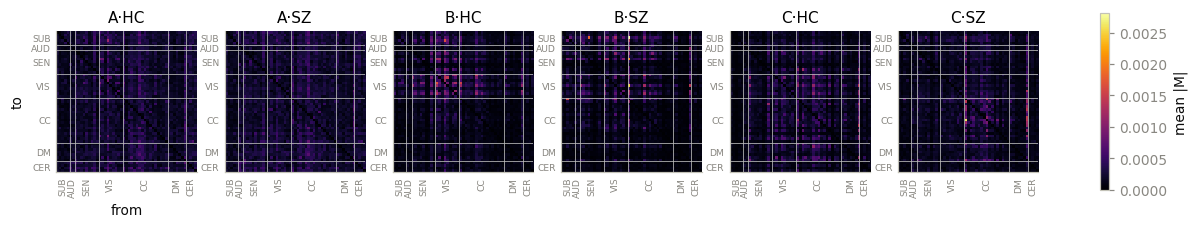

In [12]:
A = np.abs(data["M"][ok_t])                  # correct matrices, in the order of X
cls = np.repeat(data["y"], ok_t.sum(1))      # class of each

# states: pattern x class averages (pairs without matrices are skipped)
STATES, KEYS = [], []
for p in range(K):
    for c in range(len(CLASSES)):
        sel = (pattern == p) & (cls == c)
        if sel.any():
            STATES.append(A[sel].mean(0))
            KEYS.append((p, c))
STATES = np.stack(STATES)
LABELS = [f"{LETTERS[p]}·{CLASSES[c]}" for p, c in KEYS]
del A

display(pd.crosstab(np.array(LETTERS)[pattern], np.array(CLASSES)[cls], normalize="columns")
          .reindex(columns=CLASSES, fill_value=0).round(3).rename_axis(index="pattern", columns="class"))

# the classes of a pattern side by side, about 6 panels per row
per_row = max(1, 6 // len(CLASSES))
cols = len(CLASSES) * min(K, per_row)
fig, axes = plt.subplots(-(-K // per_row), cols, figsize=(2.3 * cols + 0.6, 2.6 * -(-K // per_row)), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for W, (p, c), label in zip(STATES, KEYS, LABELS):
    ax = axes[p // per_row, (p % per_row) * len(CLASSES) + c]
    ax.axis("on")
    im = heatmap(ax, W, vmax=STATES.max(), title=label)
axes[0, 0].set(xlabel="from", ylabel="to")
fig.colorbar(im, ax=axes, shrink=0.8, label="mean |M|")
save(fig, "class_patterns")
plt.show()

## 5. Stage 3: second-order dynamics

Every matrix, correctly classified or not, is mapped to its closest state (highest
correlation of |M|), turning each scan into a sequence of states. Transitions between consecutive
states are counted per class (columns: from, rows: to) and normalized to sum to 100. Class differences
are tested on subject-level frequencies (Mann-Whitney U for two classes, Kruskal-Wallis for more,
FDR-corrected); outlined cells of the deltas are significant at `ALPHA`, and only the top `DELTA_TOP`%
|delta| are colored.

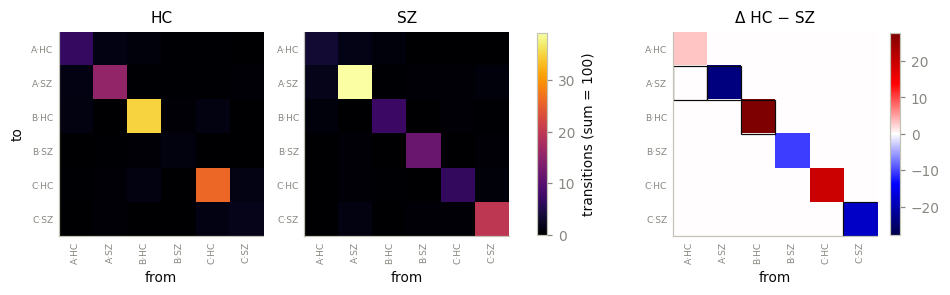

,from,to,HC,SZ,q
1,A·SZ,A·SZ,15.5322,39.0887,0.0018
0,A·HC,A·SZ,1.2544,1.7386,0.0431
2,B·HC,B·HC,34.8460,7.1942,0.0431
3,C·SZ,C·SZ,1.7709,19.7842,0.0431


In [13]:
def closest(M, states):
    """Index of the state best correlated with each |M| (ignores scale)."""
    def unit(a):
        a = a - a.mean(1, keepdims=True)
        return a / np.linalg.norm(a, axis=1, keepdims=True)

    return (unit(np.abs(M.reshape(len(M), -1))) @ unit(states.reshape(len(states), -1)).T).argmax(1)


def ticks(ax):
    ax.set_xticks(range(S), LABELS, rotation=90, fontsize=6)
    ax.set_yticks(range(S), LABELS, fontsize=6)
    ax.tick_params(length=0)
    ax.set_xlabel("from")


S = len(STATES)
seq = np.stack([closest(m, STATES) for m in data["M"]])     # state of every matrix [subjects, time]

# transition counts per subject (rows: to, columns: from)
counts = np.zeros((N, S, S))
for n, s in enumerate(seq):
    np.add.at(counts[n], (s[1:], s[:-1]), 1)
freq = 100 * counts / counts.sum((1, 2), keepdims=True)
group = [100 * counts[data["y"] == c].sum(0) / counts[data["y"] == c].sum() for c in range(len(CLASSES))]

# subject-level class tests per transition, FDR-corrected
pval = np.ones(S * S)
for e in range(S * S):
    v = [freq[data["y"] == c].reshape(-1, S * S)[:, e] for c in range(len(CLASSES))]
    if np.ptp(np.concatenate(v)) > 0:
        pval[e] = (mannwhitneyu(*v) if len(v) == 2 else kruskal(*v)).pvalue
q = false_discovery_control(pval).reshape(S, S)

# per-class matrices, then deltas of each class pair
pairs = [(a, b) for a in range(len(CLASSES)) for b in range(a + 1, len(CLASSES))]
fig, axes = plt.subplots(1, len(CLASSES) + len(pairs), figsize=(3.4 * (len(CLASSES) + len(pairs)), 3.4))
for ax, g, name in zip(axes, group, CLASSES):
    im = ax.imshow(g, cmap=ABS, vmin=0, vmax=max(x.max() for x in group))
    ticks(ax)
    ax.set_title(name)
axes[0].set_ylabel("to")
fig.colorbar(im, ax=axes[:len(CLASSES)], shrink=0.7, label="transitions (sum = 100)")

for ax, (a, b) in zip(axes[len(CLASSES):], pairs):
    d = group[a] - group[b]
    d[np.abs(d) < np.percentile(np.abs(d), 100 - DELTA_TOP)] = 0
    lim = np.abs(d).max() or 1
    im = ax.imshow(d, cmap=SIGNED, vmin=-lim, vmax=lim)
    for i, j in zip(*np.nonzero(q < ALPHA)):
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=0.8))
    ticks(ax)
    ax.set_title(f"Δ {CLASSES[a]} − {CLASSES[b]}")
    fig.colorbar(im, ax=ax, shrink=0.7)
save(fig, "second_order")
plt.show()

# significant transitions
rows = [(LABELS[j], LABELS[i], *(g[i, j] for g in group), q[i, j]) for i, j in zip(*np.nonzero(q < ALPHA))]
sig = pd.DataFrame(rows, columns=["from", "to", *CLASSES, "q"]).sort_values("q")
if len(sig):
    display(sig.round(4))
else:
    print(f"no transition differs at FDR {ALPHA}")

## 6. Connectograms

Functional patterns as directed graphs: arrows point from the source region (matrix column) to the
target (row), and the two directions of a pair bend to opposite sides. Left: regions, edges above the
`PERCENTILE`-th percentile. Right: domains, all block-averaged connections between them. Darker,
thicker edges are stronger.

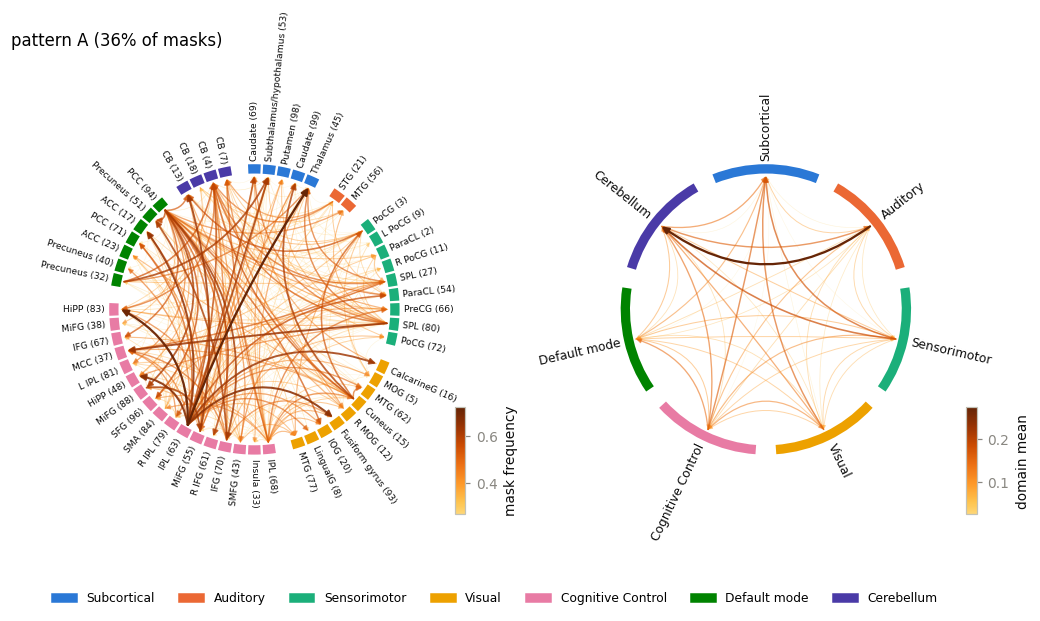

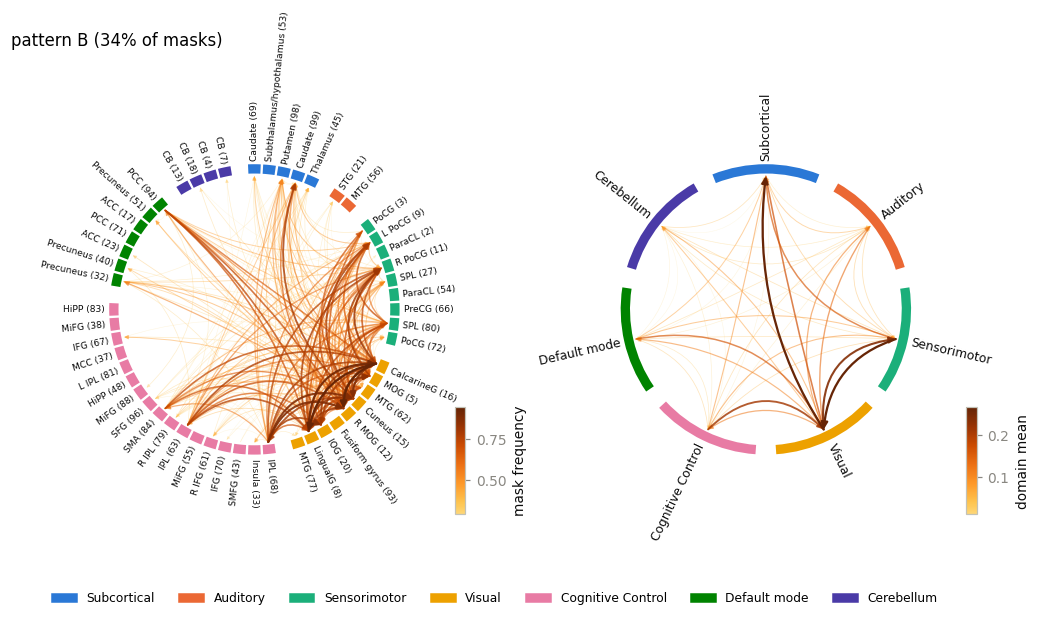

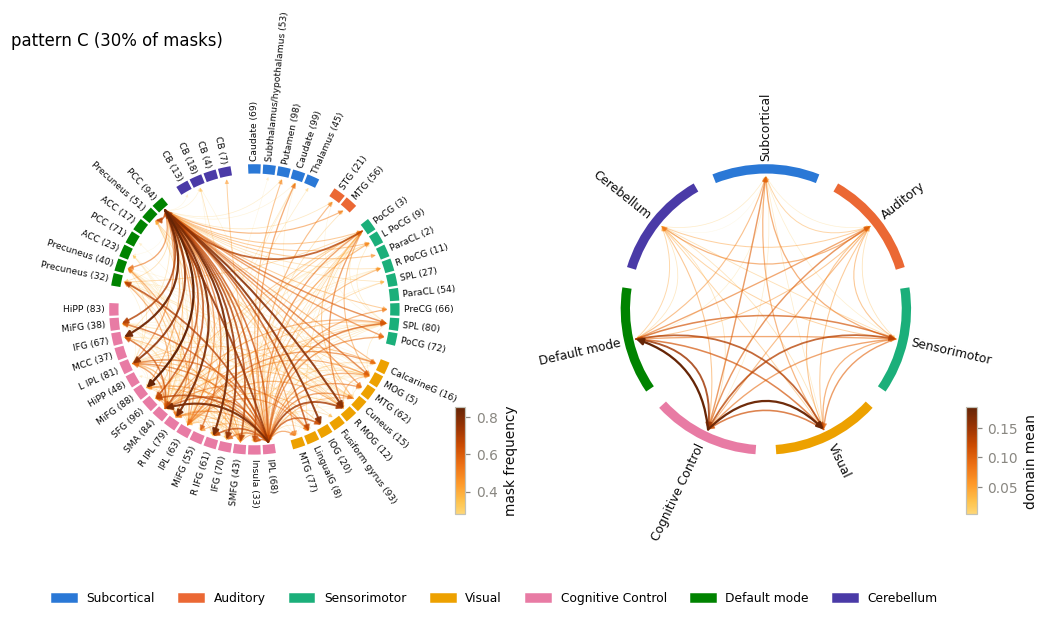

In [14]:
panels = 2 if len(DOMAINS) > 1 else 1    # domain panel needs domains
legend = [Patch(color=DCOLOR[d], label=d) for d in DOMAINS]
for P, l, s in zip(PATTERNS, LETTERS, share[K][rank]):
    fig, axes = plt.subplots(1, panels, figsize=(5.5 * panels, 5.2), squeeze=False)
    scale = connectogram(axes[0, 0], P[np.ix_(ORDER, ORDER)], [NAMES[i] for i in ORDER],
                         [DCOLOR[DOMAIN[i]] for i in ORDER], groups=[DOMAIN[i] for i in ORDER])
    fig.colorbar(scale, cax=axes[0, 0].inset_axes([0.97, 0.02, 0.025, 0.25]), label="mask frequency")
    if panels == 2:
        scale = connectogram(axes[0, 1], by_domain(P), DOMAINS, [DCOLOR[d] for d in DOMAINS], top=100, fontsize=8)
        fig.colorbar(scale, cax=axes[0, 1].inset_axes([0.97, 0.02, 0.025, 0.25]), label="domain mean")
        fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=min(len(legend), 7),
                   frameon=False, fontsize=8)
    fig.suptitle(f"pattern {l} ({s:.0%} of masks)", x=0.1, ha="left")
    save(fig, f"connectogram_{l}")
    plt.show()